<a href="https://colab.research.google.com/github/abhinayacs24-sudo/BIS_Lab/blob/main/lab_3_particle_swarm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Test Accuracy: 95.61 %
Best Loss: 0.0602


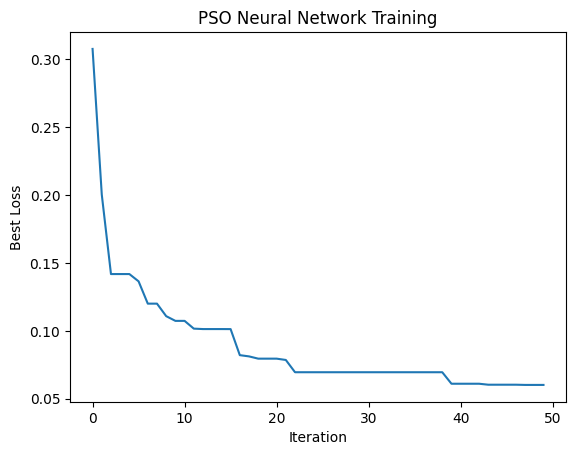

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Load dataset
data = load_breast_cancer()
X = StandardScaler().fit_transform(data.data)
y = data.target.reshape(-1, 1)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Neural network: 30 inputs, 8 hidden neurons, 1 output
D = X.shape[1] * 8 + 8 + 8 + 1

def predict(p, X):
    a = X.shape[1] * 8
    W1 = p[:a].reshape(X.shape[1], 8)
    b1 = p[a:a+8]
    W2 = p[a+8:a+16].reshape(8, 1)
    b2 = p[-1]
    h = np.tanh(X @ W1 + b1)
    return 1 / (1 + np.exp(-np.clip(h @ W2 + b2, -500, 500)))

def fitness(p):
    q = predict(p, X_train)
    return -np.mean(y_train*np.log(q+1e-9) +
                    (1-y_train)*np.log(1-q+1e-9))

# PSO parameters
np.random.seed(42)
N, iterations, w, c1, c2 = 20, 50, 0.7, 1.5, 1.5
x = np.random.uniform(-1, 1, (N, D))
v = np.zeros_like(x)
pb = x.copy()
pf = np.array([fitness(p) for p in x])
gb = pb[np.argmin(pf)].copy()
history = []

for t in range(iterations):
    for i in range(N):
        f = fitness(x[i])
        if f < pf[i]:
            pb[i], pf[i] = x[i].copy(), f
        if f < fitness(gb):
            gb = x[i].copy()
        v[i] = (w*v[i] + c1*np.random.rand(D)*(pb[i]-x[i])
                + c2*np.random.rand(D)*(gb-x[i]))
        x[i] += v[i]
    history.append(fitness(gb))

# Results
pred = (predict(gb, X_test) >= 0.5).astype(int)
print("Test Accuracy:", round(accuracy_score(y_test, pred)*100, 2), "%")
print("Best Loss:", round(fitness(gb), 4))

plt.plot(history)
plt.xlabel("Iteration")
plt.ylabel("Best Loss")
plt.title("PSO Neural Network Training")
plt.show()